In [ ]:
# ==============================================================
# Proyecto Final - Ciencia Computacional Intermedia (Tercer corte)
# Confiabilidad y planeación de capacidad de un servicio de inferencia de IA
# Grupo 1: Henry Cantor, Santiago Fajardo, Sebastián Páez, Sebastián Acuña
# ==============================================================
# Identificación del grupo (requisito del entregable E1).
# El grupo tiene 4 integrantes, así que cada C es la suma de las cédulas de una pareja:
#   C1 = Henry Cantor + Santiago Fajardo
#   C2 = Sebastián Páez + Sebastián Acuña
C1 = 2125981045
C2 = 2154025811
S = C1 + C2

print(f"C1 = {C1}")
print(f"C2 = {C2}")
print(f"S  = {S}")


C1 = 2125981045
C2 = 2154025811
S  = 4280006856


In [ ]:
# Librerías permitidas por el enunciado (Sección 6.1)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, optimize

# Única fuente de aleatoriedad de todo el notebook (requisito E1)
rng = np.random.default_rng(S)

# Parámetros personalizados del grupo (Sección 3 del enunciado)
tau = 180 + 10 * (S % 9)                    # umbral de latencia del SLO (ms)
epsilon = 0.01 * (1 + S % 3)                   # proporción máxima tolerada con L > tau
alpha = {0: 0.10, 1: 0.05, 2: 0.01}[S % 3]     # nivel de confianza = 1 - alpha
nivel_confianza = 1 - alpha
g = round(1.4 + 0.1 * (S % 7), 2)              # factor de crecimiento de la tasa de llegadas
t1_kb = 80 + 10 * (S % 5)                      # frontera pequeña / mediana (KB)
t2_kb = 400 + 25 * (S % 5)                     # frontera mediana / grande (KB)
pi_incidentes = (4 + S % 6) / 1000             # prevalencia de incidentes en producción (por minuto)
k_max = 4 + (S % 5)                            # máximo de falsas alarmas por día toleradas
r = S % 6                                      # desplazamiento entero (ítem B4)
N = 10 + (S % 11)                              # solicitudes consecutivas (ítem C4)
c0 = 2                                         # GPUs del pool real

parametros = pd.DataFrame({
    "Símbolo": ["tau (ms)", "epsilon", "1 - alpha", "g", "t1 (KB)", "t2 (KB)", "pi", "k_max", "r", "N", "c0"],
    "Valor": [tau, epsilon, nivel_confianza, g, t1_kb, t2_kb, pi_incidentes, k_max, r, N, c0],
})
parametros


,Símbolo,Valor
0,tau (ms),210.000
1,epsilon,0.010
2,1 - alpha,0.900
3,g,2.000
4,t1 (KB),90.000
5,t2 (KB),425.000
6,pi,0.004
7,k_max,5.000
8,r,0.000
9,N,14.000


In [ ]:
# Estilo y utilidades comunes para cumplir las normas de la Sección 6.1:
# título, ejes con unidades, leyenda si hay más de una serie, resolución legible
# y un pie de figura que diga qué debe concluir el lector.
import os

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
})

CARPETA_FIGURAS = "figuras"
os.makedirs(CARPETA_FIGURAS, exist_ok=True)


def pie_de_figura(fig, numero, conclusion):
    """Agrega debajo de la figura el pie 'Figura n. <conclusión para el lector>'."""
    fig.text(0.5, -0.02, f"Figura {numero}. {conclusion}",
             ha="center", va="top", wrap=True, fontsize=10, style="italic")


def guardar_figura(fig, numero):
    """Guarda la figura como figuras/figura_<n>.png para insertarla en el informe."""
    ruta = os.path.join(CARPETA_FIGURAS, f"figura_{numero}.png")
    fig.savefig(ruta, bbox_inches="tight")
    return ruta


def formatear_intervalo(estimacion, inferior, superior, metodo, decimales=3):
    """Texto de un intervalo con estimación puntual, extremos, nivel y método (Sección 6.1)."""
    d = decimales
    return (f"{estimacion:.{d}f}  [{inferior:.{d}f}, {superior:.{d}f}]  "
            f"(IC {nivel_confianza:.0%}, método: {metodo})")


In [ ]:
# Carga del paquete de datos único del grupo (entregado por el docente).
# Suban los CSV al panel de Archivos de Colab, o monten Google Drive y cambien RUTA_DATOS.
from pathlib import Path

RUTA_DATOS = Path(".")
ARCHIVOS = {
    "solicitudes": "solicitudes.csv",
    "monitoreo": "monitoreo.csv",
    # "validacion": "solicitudes_validacion.csv",  # se libera el día 9; solo se usa en el ítem F6
}

datos = {}
for nombre, archivo in ARCHIVOS.items():
    ruta = RUTA_DATOS / archivo
    if ruta.exists():
        datos[nombre] = pd.read_csv(ruta)
        print(f"{archivo}: {datos[nombre].shape[0]} filas x {datos[nombre].shape[1]} columnas")
    else:
        print(f"Falta {archivo} en {ruta.resolve().parent}")


solicitudes.csv: 39489 filas x 10 columnas
monitoreo.csv: 6000 filas x 4 columnas


# Parte A - Auditoría y preparación de los datos (8 pts)

### A1. Auditoría de `solicitudes.csv`
Inconsistencias encontradas y su tratamiento. Tabla "filas afectadas / criterio / tratamiento".

LECTURA DEL ARCHIVO

para ver si llgo como se esperaba

In [ ]:
ARCHIVO = "solicitudes.csv"#archivo que se va a auditar.
T_VENTANA = 1200.0#duracion de la ventana de observacion
TOL_MS = None#tolerancia en ms para comparar tiempos
VERSIONES_VALIDAS = {"A", "B"}#etiquetas permitidas de la columna
COLS_NUM =["id_solicitud", "t_llegada_s", "tam_kb", "cache_hit", "red_ms",
           "gpu_ms", "latencia_ms", "intentos", "exito"]
COLS_ESPERADAS = ["id_solicitud", "t_llegada_s", "tam_kb", "cache_hit", "version", "red_ms",
                  "gpu_ms", "latencia_ms", "intentos", "exito"]
UMBRAL_REPETICION = 8#veces que se puede repetir un valor decimal antes de pensar que es centinela
FACTOR_REPETICION = 8 #debe repetirse este multiplo de lo que se repiten sus valores vecinos
TAM_FACTOR_MEDIANA = 25 #un tam_kb mayor a este multiplo es implausible
BYTES_POR_KB = 1024 #factor de conversion si el factor esta en bytes
ALPHA_EVIDENCIA = 0.05 #nivel de la prueba KS que respalda la coreccion de unidades

In [ ]:
df_raw = pd.read_csv(ARCHIVO)#lee el archivo
df = df_raw.copy()#copia sobre la que operamos

faltan = [c for c in COLS_ESPERADAS if c not in df.columns]#columnas que faltan
sobran = [c for c in df.columns if c not in COLS_ESPERADAS]#columnas que sobran
print("formas(filas, columnas):", df.shape)#tamano del archivo
print("columnas que faltan:", faltan, "/ columnas extra:", sobran)
print("\ntipos de dato leidos por pandas")
print(df.dtypes)#columna marcada como object, significa texto mezclado o comas decimales

formas(filas, columnas): (39489, 10)
columnas que faltan: [] / columnas extra: []

tipos de dato leidos por pandas
id_solicitud      int64
t_llegada_s     float64
tam_kb          float64
cache_hit         int64
version          object
red_ms          float64
gpu_ms          float64
latencia_ms     float64
intentos          int64
exito             int64
dtype: object


In [ ]:
#conversion a numerico, sino se puede pasa a NaN y se cuenta
no_numericos = {}#guardamos esos valores
for c in COLS_NUM:#recorre cada columna que debe ser numerica
  antes = df[c].isna().sum()#ausentes que ya tenia la columna
  df[c] = pd.to_numeric(df[c], errors="coerce")#convierte a numero, el que no se pueda pasa NaN
  no_numericos[c] = int(df[c].isna().sum() - antes)#nuevos valores NaN
print("valores no numericos convertidos a NaN por columna:", no_numericos)

valores no numericos convertidos a NaN por columna: {'id_solicitud': 0, 't_llegada_s': 0, 'tam_kb': 0, 'cache_hit': 0, 'red_ms': 0, 'gpu_ms': 0, 'latencia_ms': 0, 'intentos': 0, 'exito': 0}


In [ ]:
print("ausentes por columna:")
print(df.isna().sum())#conteo de celdas vacias en cada columna
print("\nresumen numerico (minimos, cuantiles y maixmos):")
print(df[COLS_NUM].describe(percentiles=[.01, .5, .99]).T.round(2))
for c in ["version", "cache_hit", "intentos", "exito"]:
  print(f"\nfrecuencias de {c}:")
  print(df[c].value_counts(dropna=False))

ausentes por columna:
id_solicitud     0
t_llegada_s      0
tam_kb           0
cache_hit        0
version          0
red_ms          39
gpu_ms          39
latencia_ms      0
intentos         0
exito            0
dtype: int64

resumen numerico (minimos, cuantiles y maixmos):
                count      mean       std   min      1%       50%       99%        max
id_solicitud  39489.0  19688.26  11364.08  1.00  394.88  19688.00  38978.12   39371.00
t_llegada_s   39489.0    580.78    323.46  0.01   15.41    523.95   1186.28    1199.99
tam_kb        39489.0    592.93  10994.35  1.08   18.85    204.14    826.50  725841.92
cache_hit     39489.0      0.34      0.47  0.00    0.00      0.00      1.00       1.00
red_ms        39450.0     25.60      3.87  7.32   16.49     25.59     34.55      40.09
gpu_ms        39450.0     26.03     28.01  0.00    0.00     21.35    117.40     295.47
latencia_ms   39489.0     62.61     46.70 -1.00   17.52     50.99    245.95     448.04
intentos      39489.0      1.

como el archivo almacena tiempos redondeados (0,01ms), la regla L = red + espera + GPU se cumple unicamente bajo el redondeo. Medimos ese redondeo para declarar los errores.

In [ ]:
def decimales(s, maximo=6):
    """Mínimo número de decimales k tal que redondear la serie a k decimales no la cambia (hasta `maximo`)."""
    x = s.dropna().to_numpy(dtype=float)#valores presentes como arreglo numpy
    for k in range(maximo + 1):#prueba con 0,1,2.. decimales
      if np.allclose(np.round(x, k), x, rtol=0, atol=1e-9):#si redondeamos k decimales, queda igual?
        return k#el primer k que funciona es la resolucion del archivo
    return maximo#si ninguno funciona, el archivo esta bien de precision
DEC_TIEMPOS = max(decimales(df.red_ms), decimales(df.gpu_ms), decimales(df.latencia_ms))#decimales de los tiempos
RESOLUCION_MS = 10.0 ** -DEC_TIEMPOS  #resolucion dos decimales
if TOL_MS is None:#sino se fija a mano se deduce la resolucion
    TOL_MS = 1.5 * RESOLUCION_MS + 1e-9 #1,5 resoluciones + margen numerico diminuto
print(f"Decimales de los tiempos: {DEC_TIEMPOS} | resolución: {RESOLUCION_MS} ms | TOL_MS = {TOL_MS}")

Decimales de los tiempos: 2 | resolución: 0.01 ms | TOL_MS = 0.015000000999999999


In [ ]:
esp_tmp = df.latencia_ms - df.red_ms - df.gpu_ms #espera implicita, deberia de ser >=0
peq = esp_tmp[(esp_tmp < -1e-9) & (esp_tmp > -10 * RESOLUCION_MS)]#espera negativa (candidata a redondeo)
print("Esperas negativas pequeñas (|valor| < 10 resoluciones) y cuántas veces aparece cada una:")
print(peq.round(DEC_TIEMPOS + 2).value_counts().sort_index())#si salen uns poco valores fijos, va aredondeo
# Verificación complementaria: en filas con caché la espera es 0 por definición (L = red). Si el redondeo ya
# está «incluido» en ambos números, esa diferencia es 0 y NO delata el ruido
solo_cache = df[(df.cache_hit == 1) & (df.gpu_ms == 0)]#filas con cache y sin GPU
ruido = (solo_cache.latencia_ms - solo_cache.red_ms).abs()#tamano de la diferencia de esas filas
print("\nCuantiles de |latencia - red| en filas con caché (ms):")
print(ruido.quantile([.5, .9, .99, .999, 1]))#cuantiles altos pueden estar exgaerados por filas defectuosas

Esperas negativas pequeñas (|valor| < 10 resoluciones) y cuántas veces aparece cada una:
-0.01    2134
Name: count, dtype: int64

Cuantiles de |latencia - red| en filas con caché (ms):
0.500     0.00000
0.900     0.00000
0.990     0.00000
0.999    27.71946
1.000    35.56000
dtype: float64


REGLAS DE VALIDACION

In [ ]:
def reglas(d):
    """Devuelve {codigo: (tipo, criterio, mascara)} con todas las reglas aplicadas al DataFrame d."""
    esp = d.latencia_ms - d.red_ms - d.gpu_ms                # espera en cola implícita (ms): L = red + espera + GPU, con espera >= 0
    r = {}                                                   # diccionario de resultados
    # --- duplicados -----------------------------------------------------------------------
    r["R01"] = ("error", "Fila duplicada exacta (copia de otra fila)",
                d.duplicated(keep="first"))                  # True en la 2.ª copia en adelante; la 1.ª se conserva
    r["R02"] = ("error", "id_solicitud repetido con contenido distinto",
                d.id_solicitud.duplicated(keep=False) & ~d.duplicated(keep=False))  # mismo id pero filas no idénticas
    # --- ausentes y no finitos ----------------------------------------------------------------
    for c in COLS_ESPERADAS:                                 # una regla por columna
        if c in d.columns:                                   # solo si la columna existe
            if c == "version":                               # texto: solo puede estar ausente
                m = d[c].isna()
            else:                                            # numéricas: ausente o infinito
                m = d[c].isna() | np.isinf(d[c])
            r[f"R03_{c}"] = ("error", f"{c} ausente, no numérico o infinito", m)
    # --- rangos físicos -----------------------------------------------------------------------
    r["R04"] = ("error", f"t_llegada_s fuera de [0, {T_VENTANA:.0f}] s",
                (d.t_llegada_s < 0) | (d.t_llegada_s > T_VENTANA))     # llegada fuera de la ventana observada
    r["R05"] = ("error", "tam_kb <= 0 (una imagen tiene tamaño positivo)", d.tam_kb <= 0)
    r["R18"] = ("error", f"tam_kb mayor que {TAM_FACTOR_MEDIANA} veces la mediana (posible error de unidades)",
                d.tam_kb > TAM_FACTOR_MEDIANA * d.tam_kb.median())     # un tamaño absurdamente grande respecto al resto
    r["R06"] = ("error", "red_ms <= 0 (un tiempo de red es positivo)", d.red_ms <= 0)
    r["R07"] = ("error", "gpu_ms < 0 (un tiempo no es negativo)", d.gpu_ms < 0)
    r["R16"] = ("error", "latencia_ms <= 0 (incluye el valor centinela -1)", d.latencia_ms <= 0)
    # --- dominios de variables discretas ------------------------------------------------------
    r["R08"] = ("error", "cache_hit distinto de 0 y 1", d.cache_hit.notna() & ~d.cache_hit.isin([0, 1]))
    r["R11"] = ("error", "version fuera de {A, B} (etiqueta mal escrita)", d.version.notna() & ~d.version.isin(VERSIONES_VALIDAS))
    r["R12"] = ("error", "intentos fuera de {1, 2, 3} (el SDK abandona tras 3)", d.intentos.notna() & ~d.intentos.isin([1, 2, 3]))
    r["R13"] = ("error", "exito distinto de 0 y 1", d.exito.notna() & ~d.exito.isin([0, 1]))
    # --- coherencia entre columnas -----------------------------------------------------------
    r["R09"] = ("error", "cache_hit = 1 pero gpu_ms > 0 (la caché no usa GPU)", (d.cache_hit == 1) & (d.gpu_ms > 0))
    r["R10"] = ("error", "cache_hit = 0 pero gpu_ms <= 0 (si usó GPU, G > 0)", (d.cache_hit == 0) & (d.gpu_ms <= 0))
    r["R14"] = ("error", "exito = 0 con menos de 3 intentos (abandona solo tras 3 fallos)", (d.exito == 0) & (d.intentos < 3))
    r["R15"] = ("error", "latencia < red + gpu más allá del redondeo (espera negativa)", esp < -TOL_MS)
    # --- observaciones informativas --------------------------------------------------------------
    r["R17"] = ("info", "Fila fuera de orden temporal (t menor que la fila anterior)", d.t_llegada_s.diff() < 0)
    return r

def tabla_auditoria(d):
    """Cuenta las filas que viola cada regla y devuelve la tabla de auditoría."""
    filas = []                                               # una fila de la tabla por cada regla
    for cod, (tipo, criterio, m) in reglas(d).items():
        filas.append({"regla": cod, "tipo": tipo, "criterio": criterio,
                      "filas_afectadas": int(m.sum()),       # cuántas filas violan la regla
                      "pct_del_total": round(100 * m.mean(), 3)})   # porcentaje sobre todas las filas
    return pd.DataFrame(filas)

aud = tabla_auditoria(df)                                    # auditoría del archivo tal como llegó
pd.set_option("display.width", 200, "display.max_colwidth", 90)   # que la tabla se vea completa en pantalla
print(aud[aud.filas_afectadas > 0].to_string(index=False))   # solo las reglas que sí encontraron algo
print("\nReglas sin hallazgos (revisadas y limpias):", list(aud[aud.filas_afectadas == 0].regla))

     regla  tipo                                                         criterio  filas_afectadas  pct_del_total
       R01 error                       Fila duplicada exacta (copia de otra fila)              114          0.289
       R02 error                     id_solicitud repetido con contenido distinto                8          0.020
R03_red_ms error                           red_ms ausente, no numérico o infinito               39          0.099
R03_gpu_ms error                           gpu_ms ausente, no numérico o infinito               39          0.099
       R18 error tam_kb mayor que 25 veces la mediana (posible error de unidades)               59          0.149
       R16 error                 latencia_ms <= 0 (incluye el valor centinela -1)              118          0.299
       R15 error     latencia < red + gpu más allá del redondeo (espera negativa)              196          0.496

Reglas sin hallazgos (revisadas y limpias): ['R03_id_solicitud', 'R03_t_llegada_s', 'R0

In [ ]:
# Filas afectadas por AL MENOS una regla de tipo error (una fila puede violar varias reglas a la vez)
mascaras = {k: v[2] for k, v in reglas(df).items() if v[0] == "error"}      # solo las reglas de tipo error
hay_error = pd.concat(mascaras, axis=1).any(axis=1)                          # True si la fila viola cualquiera
print(f"Filas con al menos un error: {hay_error.sum()} de {len(df)} ({100 * hay_error.mean():.2f} %)")
print("Suma de las columnas filas_afectadas:", int(aud[aud.tipo == 'error'].filas_afectadas.sum()),
      "(puede superar la cifra anterior porque hay filas que violan varias reglas)")

Filas con al menos un error: 451 de 39489 (1.14 %)
Suma de las columnas filas_afectadas: 573 (puede superar la cifra anterior porque hay filas que violan varias reglas)


BUSQUEDA DE VALORES CENTINELA

In [ ]:
def repetidos_atipicos(s, dec, umbral, factor, vecinos=5):
    """Valores que aparecen >= umbral veces y >= factor veces la mediana de sus `vecinos` vecinos a cada lado."""
    res = 10.0 ** -dec                                       # distancia entre valores consecutivos posibles
    vc = s.dropna().round(dec).value_counts()                # cuántas veces aparece cada valor
    filas = []                                               # resultados
    for valor, n in vc[vc >= umbral].items():                # solo valores que se repiten lo suficiente
        vec = [vc.get(round(valor + k * res, dec), 0)        # veces que aparecen los valores vecinos
               for k in range(-vecinos, vecinos + 1) if k != 0]
        base = max(float(np.median(vec)), 1.0)               # repetición típica del entorno (mínimo 1)
        if n >= factor * base:                               # si el valor destaca mucho sobre su entorno
            filas.append((valor, int(n), base))
    return filas

sin_dup = df.drop_duplicates()                                # primero se quitan copias exactas, que repetirían todos los valores
reps = []                                                     # aquí se juntan los hallazgos
for c in ["tam_kb", "red_ms", "gpu_ms", "latencia_ms"]:       # columnas continuas
    dec = decimales(sin_dup[c])                               # resolución propia de cada columna
    for valor, n, base in repetidos_atipicos(sin_dup[c], dec, UMBRAL_REPETICION, FACTOR_REPETICION):
        reps.append({"columna": c, "valor": valor, "veces": n, "repeticion_tipica_vecinos": base})
reps = pd.DataFrame(reps)
print(reps.sort_values("veces", ascending=False).head(20).to_string(index=False) if len(reps) else "Sin valores atípicamente repetidos")
# Interpretación: gpu_ms = 0 es legítimo (caché). Cualquier otro valor que destaque (p. ej. -1 en latencia_ms) merece revisión.

    columna  valor  veces  repeticion_tipica_vecinos
     gpu_ms   0.00  13232                        1.0
latencia_ms  -1.00    118                        1.0
     gpu_ms   8.73      8                        1.0


EVIDENCIA QUE NOS AYUDA PARA DECIDIR EL TRATAMIENTO.

In [ ]:
# -a. R09: caché con GPU -> ¿qué campo es el erróneo? (se usa la identidad L = red + espera + GPU)
c9 = df[(df.cache_hit == 1) & (df.gpu_ms > 0)].copy()        # filas de la regla R09
c9["dif_lat_red"] = (c9.latencia_ms - c9.red_ms).abs()       # si es ~0, la latencia es la de una respuesta SIN GPU
c9["dif_lat_red_gpu"] = (c9.latencia_ms - c9.red_ms - c9.gpu_ms).abs()   # si es ~0, la latencia sí incluye la GPU
culpa_gpu = (c9.dif_lat_red <= TOL_MS)                       # la latencia coincide con «sin GPU»: el campo erróneo es gpu_ms
culpa_cache = (c9.dif_lat_red_gpu <= TOL_MS) & ~culpa_gpu    # la latencia incluye la GPU: el campo erróneo es cache_hit
print(f"R09: {len(c9)} filas | gpu_ms es el campo erróneo: {int(culpa_gpu.sum())} | "
      f"cache_hit es el campo erróneo: {int(culpa_cache.sum())} | sin evidencia: {int((~culpa_gpu & ~culpa_cache).sum())}")

R09: 0 filas | gpu_ms es el campo erróneo: 0 | cache_hit es el campo erróneo: 0 | sin evidencia: 0


In [ ]:
# -b. R18: tam_kb implausible -> ¿es un error de unidades (bytes en vez de KB)?
umbral_tam = TAM_FACTOR_MEDIANA * df.tam_kb.median()          # umbral fijo de implausibilidad (se usará también al limpiar)
grandes = df[df.tam_kb > umbral_tam].drop_duplicates()        # filas implausibles (sin copias repetidas)
normales = df.loc[df.tam_kb <= umbral_tam, "tam_kb"]          # tamaños normales, para comparar
DEC_TAM = decimales(normales)                                 # resolución con la que se guardan los tamaños normales
CORREGIR_TAM = False                                          # por defecto no se corrige; la evidencia puede cambiarlo
print(f"Umbral de implausibilidad: {umbral_tam:.1f} KB | filas implausibles: {len(grandes)} | "
      f"mayor tamaño normal: {normales.max():.1f} KB | menor tamaño implausible: "
      f"{grandes.tam_kb.min() if len(grandes) else float('nan'):.1f} KB")
if len(grandes) > 0:
    q = grandes.tam_kb / BYTES_POR_KB                         # tamaños implausibles reinterpretados como bytes -> KB
    frac_exacta = float((np.abs(np.round(q, DEC_TAM) - q) < 1e-6).mean())   # ¿al dividir quedan con la misma resolución que los normales?
    ks_p = float(stats.ks_2samp(q, normales.dropna()).pvalue)   # ¿se distribuyen como los tamaños normales? (p alto = sí)
    print(f"Tras dividir entre {BYTES_POR_KB}: fracción con exactamente {DEC_TAM} decimales = {frac_exacta:.3f} "
          f"| mediana {q.median():.1f} KB frente a {normales.median():.1f} KB normales | KS p = {ks_p:.3f}")
    print("Reparto de las filas implausibles por versión:", grandes.version.value_counts().to_dict(),
          "| por caché:", grandes.cache_hit.value_counts().to_dict())
    CORREGIR_TAM = (frac_exacta >= 0.95) and (ks_p > ALPHA_EVIDENCIA)    # criterio de decisión explícito
print("¿Se corrige dividiendo entre", BYTES_POR_KB, "? ->", CORREGIR_TAM)

Umbral de implausibilidad: 5103.5 KB | filas implausibles: 59 | mayor tamaño normal: 1697.2 KB | menor tamaño implausible: 22179.8 KB
Tras dividir entre 1024: fracción con exactamente 2 decimales = 1.000 | mediana 196.8 KB frente a 203.8 KB normales | KS p = 0.730
Reparto de las filas implausibles por versión: {'A': 34, 'B': 25} | por caché: {0: 36, 1: 23}
¿Se corrige dividiendo entre 1024 ? -> True


In [ ]:
# -c. R03: ausentes que se pueden deducir con la lógica del sistema (solo en filas con caché)
rn = df[df.red_ms.isna()]                                     # filas sin tiempo de red
gn = df[df.gpu_ms.isna()]                                     # filas sin tiempo de GPU
rec_red = int(((rn.cache_hit == 1) & (rn.latencia_ms > 0)).sum())   # con caché, L = red, así que red = latencia
rec_gpu = int((gn.cache_hit == 1).sum())                      # con caché, gpu_ms = 0 por definición
print(f"red_ms ausente: {len(rn)} filas, deducibles (caché y latencia válida): {rec_red}, no deducibles: {len(rn) - rec_red}")
print(f"gpu_ms ausente: {len(gn)} filas, deducibles (caché): {rec_gpu}, no deducibles: {len(gn) - rec_gpu}")

red_ms ausente: 39 filas, deducibles (caché y latencia válida): 15, no deducibles: 24
gpu_ms ausente: 39 filas, deducibles (caché): 13, no deducibles: 26


TRATAMIENTO

In [ ]:
TRATAMIENTO = {                                              # código de regla -> qué se hace con las filas que la violan
    "R01": "eliminar la copia",                              # una solicitud ocurre una sola vez
    "R02": "conservar la copia consistente con la identidad de tiempos si hay exactamente una; si no, eliminar todas",
    "R03": "corregir si es deducible (caché); si no, eliminar",   # ausentes: solo se corrige lo que la lógica permite deducir
    "R04": "eliminar", "R05": "eliminar", "R06": "eliminar", "R07": "eliminar", "R16": "eliminar",  # valores físicamente imposibles
    "R08": "eliminar", "R12": "eliminar", "R13": "eliminar", # dominios inválidos sin forma de recuperar el valor correcto
    "R09": "corregir gpu_ms = 0 si la latencia coincide con «sin GPU»; si no, eliminar",  # decisión basada en la evidencia 5a
    "R10": "eliminar",                                       # no se puede recuperar el tiempo de GPU
    "R11": "normalizar la etiqueta (quitar espacios y pasar a mayúscula); si sigue inválida, eliminar",
    "R14": "eliminar",                                       # no se sabe si el error está en exito o en intentos
    "R15": "eliminar",                                       # la identidad no se cumple más allá del redondeo y no hay cómo repararla
    "R17": "conservar (informativa); se ordena por tiempo al final",
    "R18": "dividir entre 1024 si la evidencia 5b lo respalda; si no, eliminar",   # error de unidades (bytes en vez de KB)
}

In [ ]:
def limpiar(d):
    """Aplica el tratamiento en orden y devuelve (d_limpio, flujo), donde flujo registra cuántas filas se pierde en cada paso."""
    d = d.copy()                                             # no modificar el DataFrame de entrada
    flujo = [("Filas iniciales", len(d))]                    # lista de (paso, filas restantes)

    d = d[~d.duplicated(keep="first")]                       # paso 1: eliminar copias exactas ANTES de contar otros defectos
    flujo.append(("Quitar duplicados exactos (R01)", len(d)))

    d["version"] = d.version.astype("string").str.strip().str.upper()   # paso 2: normalizar la etiqueta (espacios y mayúsculas)
    flujo.append(("Normalizar etiqueta version (R11), sin perder filas", len(d)))

    # paso 3: correcciones que la lógica del sistema permite DEDUCIR (no se pierden filas)
    cond9 = (d.cache_hit == 1) & (d.gpu_ms > 0) & ((d.latencia_ms - d.red_ms).abs() <= TOL_MS)   # R09 con evidencia a favor de gpu_ms
    d.loc[cond9, "gpu_ms"] = 0.0                             # la caché no usa GPU
    flujo.append((f"Corregir gpu_ms = 0 en caché (R09), {int(cond9.sum())} filas, sin perder filas", len(d)))

    if CORREGIR_TAM:                                         # R18: solo si la evidencia de la sección 5b lo respaldó
        cond18 = d.tam_kb > umbral_tam                       # filas con tamaño implausible
        d.loc[cond18, "tam_kb"] = (d.loc[cond18, "tam_kb"] / BYTES_POR_KB).round(DEC_TAM)   # bytes -> KB
        flujo.append((f"Corregir tam_kb dividiendo entre {BYTES_POR_KB} (R18), {int(cond18.sum())} filas, sin perder filas", len(d)))

    c_gpu = d.gpu_ms.isna() & (d.cache_hit == 1)             # R03: caché y gpu_ms ausente
    d.loc[c_gpu, "gpu_ms"] = 0.0                             # con caché, gpu_ms = 0 por definición
    c_red = d.red_ms.isna() & (d.cache_hit == 1) & (d.latencia_ms > 0)   # R03: caché, red ausente y latencia válida
    d.loc[c_red, "red_ms"] = d.loc[c_red, "latencia_ms"]     # con caché, L = red
    flujo.append((f"Deducir ausentes en filas con caché (R03): gpu_ms {int(c_gpu.sum())}, red_ms {int(c_red.sum())}, sin perder filas", len(d)))

    # paso 4: ids repetidos con contenido distinto (R02): quedarse con la copia sana si hay exactamente una
    rg = reglas(d)                                           # reglas sobre el estado actual
    mala = pd.concat({k: v[2] for k, v in rg.items()
                      if v[0] == "error" and k not in ("R01", "R02")}, axis=1).any(axis=1)   # fila con algún otro error
    dup_id = d.id_solicitud.duplicated(keep=False)           # filas cuyo id aparece más de una vez
    sanas = (dup_id & ~mala).astype(int).groupby(d.id_solicitud).transform("sum")   # cuántas copias sanas tiene cada id
    quitar = dup_id & mala & (sanas == 1)                    # copia defectuosa cuando existe exactamente una sana
    d = d[~quitar]
    flujo.append((f"Resolver ids repetidos (R02): quitar la copia defectuosa, {int(quitar.sum())} filas", len(d)))

    # paso 5: eliminar las filas que aún violen alguna regla de tipo error.
    # Las máscaras se calculan UNA vez sobre el estado actual de d (así todas quedan alineadas) y luego se descartan juntas.
    ya = pd.Series(False, index=d.index)                     # marca las filas ya condenadas por una regla anterior
    costo = []                                               # (regla, filas nuevas que elimina esa regla)
    for cod, (tipo, criterio, m) in reglas(d).items():       # recorre las reglas en su orden de definición
        if tipo == "error":                                  # las informativas (R17) no eliminan nada
            nuevas = int((m & ~ya).sum())                    # filas que esta regla condena y que ninguna anterior había condenado
            if nuevas > 0:
                costo.append((f"Eliminar por {cod}: {criterio}", nuevas))
            ya = ya | m                                      # acumula las filas condenadas
    d = d[~ya]                                               # descarta todas de una vez
    restantes = len(d) + sum(n for _, n in costo)            # filas antes de este paso, para ir restando una regla a la vez
    for texto, nuevas in costo:                              # registra el costo de cada regla en el flujo
        restantes -= nuevas
        flujo.append((texto, restantes))

    d = d.sort_values("t_llegada_s", kind="stable").reset_index(drop=True)   # orden temporal, requerido por los análisis siguientes
    flujo.append(("Ordenar por t_llegada_s, sin perder filas", len(d)))
    return d, pd.DataFrame(flujo, columns=["paso", "filas_restantes"])

df_limpio, flujo = limpiar(df)                               # ejecuta la limpieza
flujo["filas_perdidas"] = (-flujo.filas_restantes.diff()).fillna(0).astype(int)   # filas que se pierde en cada paso
print(flujo.to_string(index=False))

                                                                             paso  filas_restantes  filas_perdidas
                                                                  Filas iniciales            39489               0
                                                  Quitar duplicados exactos (R01)            39375             114
                              Normalizar etiqueta version (R11), sin perder filas            39375               0
                    Corregir gpu_ms = 0 en caché (R09), 0 filas, sin perder filas            39375               0
          Corregir tam_kb dividiendo entre 1024 (R18), 59 filas, sin perder filas            39375               0
Deducir ausentes en filas con caché (R03): gpu_ms 13, red_ms 15, sin perder filas            39375               0
                Resolver ids repetidos (R02): quitar la copia defectuosa, 4 filas            39371               4
                  Eliminar por R03_red_ms: red_ms ausente, no numérico o infinit

VOLVEMOS A AUDITAR PARA VERIFICAR

In [ ]:
aud_post = tabla_auditoria(df_limpio)                        # auditoría del archivo ya limpio
residual = aud_post[(aud_post.tipo == "error") & (aud_post.filas_afectadas > 0)]   # reglas de error que aún se violan
print("Reglas de error que aún se violan:\n", residual.to_string(index=False) if len(residual) else "ninguna")
assert len(residual) == 0, "La limpieza no eliminó todas las violaciones: revisa limpiar()"   # frena el notebook si algo quedó mal
print(f"\nFilas: {len(df_raw)} (original) -> {len(df_limpio)} (limpio) | perdidas: {len(df_raw) - len(df_limpio)} "
      f"({100 * (len(df_raw) - len(df_limpio)) / len(df_raw):.2f} %)")

Reglas de error que aún se violan:
 ninguna

Filas: 39489 (original) -> 39129 (limpio) | perdidas: 360 (0.91 %)


IMPACTO DE LA LIMPIEZA

In [ ]:
def resumen(d, nombre):
    """Estadísticos clave de un DataFrame de solicitudes."""
    nc = d[(d.cache_hit == 0)]                               # solicitudes que usaron GPU
    return pd.Series({"filas": len(d),
                      "latencia media (ms)": d.latencia_ms.mean(),
                      "latencia mediana (ms)": d.latencia_ms.median(),
                      "latencia p95 (ms)": d.latencia_ms.quantile(.95),
                      "P(L > tau)": (d.latencia_ms > tau).mean(),     # fracción de solicitudes por encima del umbral del SLO
                      "tasa de caché": d.cache_hit.mean(),
                      "GPU media sin caché (ms)": nc.gpu_ms.mean(),
                      "tam_kb medio": d.tam_kb.mean(),
                      "red media (ms)": d.red_ms.mean()}, name=nombre)

impacto = pd.concat([resumen(df, "original"), resumen(df_limpio, "limpio")], axis=1)   # lado a lado
impacto["cambio %"] = 100 * (impacto["limpio"] - impacto["original"]) / impacto["original"]  # variación relativa
print(impacto.round(4).to_string())
# Nota: el tam_kb medio del original está inflado por los valores en bytes; el cambio grande en esa fila es esperable y es la prueba del defecto.

                            original      limpio  cambio %
filas                     39489.0000  39129.0000   -0.9116
latencia media (ms)          62.6123     62.8166    0.3263
latencia mediana (ms)        50.9900     51.1700    0.3530
latencia p95 (ms)           154.2620    154.3020    0.0259
P(L > tau)                    0.0198      0.0199    0.2748
tasa de caché                 0.3362      0.3370    0.2586
GPU media sin caché (ms)     39.2095     39.2142    0.0121
tam_kb medio                592.9326    241.6502  -59.2449
red media (ms)               25.5985     25.5973   -0.0046


GRAFICA PARA EL INFORME

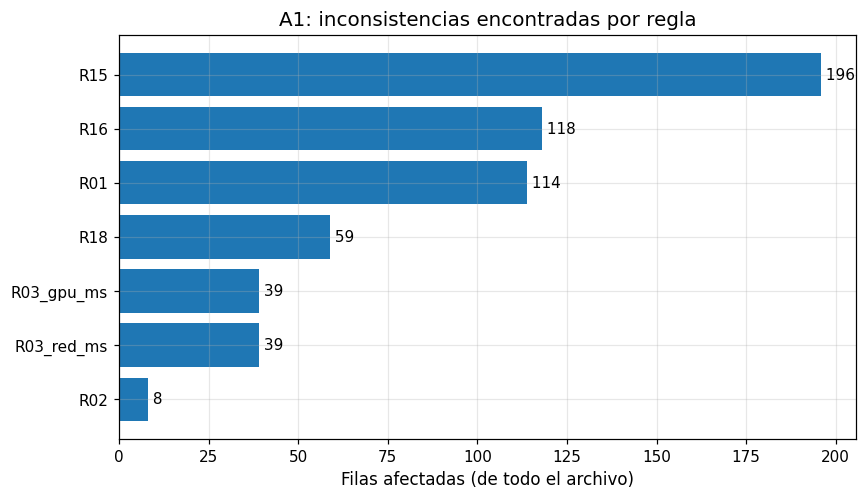

In [ ]:
aud["tratamiento"] = aud.regla.str[:3].map(TRATAMIENTO)       # une cada regla con su tratamiento (R03_x se agrupa como R03)
aud.to_csv("A1_tabla_auditoria.csv", index=False)             # tabla «filas afectadas / criterio / tratamiento» (anexo del informe)
flujo.to_csv("A1_flujo_filas.csv", index=False)               # cuántas filas se pierde en cada paso (bitácora)
df_limpio.to_csv("solicitudes_limpio.csv", index=False)       # archivo limpio que usarán A2 y las demás partes

hall = aud[aud.filas_afectadas > 0].sort_values("filas_afectadas")      # solo reglas con hallazgos, de menor a mayor
fig, ax = plt.subplots(figsize=(8, 0.45 * len(hall) + 1.5))   # alto proporcional al número de barras
ax.barh(hall.regla, hall.filas_afectadas)                     # barras horizontales: una por regla
ax.set_xlabel("Filas afectadas (de todo el archivo)")         # unidades del eje
ax.set_title("A1: inconsistencias encontradas por regla")     # título
for i, v in enumerate(hall.filas_afectadas):                  # escribe el número al final de cada barra
    ax.text(v, i, f" {v}", va="center")
plt.tight_layout()
plt.savefig("fig_A1_defectos.png", dpi=150)                   # guarda la figura para el anexo
plt.show()

In [ ]:
# Resumen en texto para la bitácora
print(f"A1 · archivo {ARCHIVO}: {len(df_raw)} filas, {df_raw.shape[1]} columnas.")
print(f"A1 · filas con al menos un error: {int(hay_error.sum())} ({100 * hay_error.mean():.2f} %).")
print(f"A1 · filas finales tras limpieza: {len(df_limpio)} (perdidas: {len(df_raw) - len(df_limpio)}).")
print(f"A1 · resolución de tiempos = {RESOLUCION_MS} ms | TOL_MS = {TOL_MS} | corrección de unidades en tam_kb = {CORREGIR_TAM}")
print(f"A1 · UMBRAL_REPETICION = {UMBRAL_REPETICION} | FACTOR_REPETICION = {FACTOR_REPETICION} | T_VENTANA = {T_VENTANA}")

A1 · archivo solicitudes.csv: 39489 filas, 10 columnas.
A1 · filas con al menos un error: 451 (1.14 %).
A1 · filas finales tras limpieza: 39129 (perdidas: 360).
A1 · resolución de tiempos = 0.01 ms | TOL_MS = 0.015000000999999999 | corrección de unidades en tam_kb = True
A1 · UMBRAL_REPETICION = 8 | FACTOR_REPETICION = 8 | T_VENTANA = 1200.0


### A2. ¿Un único régimen?
Criterio estadístico cuantitativo, segmentos, sensibilidad al criterio y régimen estable que se usará en adelante.

**Paso 1. ¿Toda la ventana es un único régimen?**

Si la tasa de llegadas fuera constante (Poisson homogéneo), los conteos en bins de 10 s tendrían varianza ≈ media. El índice de dispersión $D=\sum (c_i-\bar c)^2/\bar c$ sigue aprox. una $\chi^2_{k-1}$.

In [ ]:
d_a2 = df_limpio.sort_values("t_llegada_s").reset_index(drop=True)   # orden temporal
conteos = np.histogram(d_a2.t_llegada_s, bins=np.arange(0, T_VENTANA + 10, 10))[0]   # llegadas cada 10 s

D = ((conteos - conteos.mean())**2 / conteos.mean()).sum()     # índice de dispersión
p_disp = stats.chi2.sf(D, len(conteos) - 1)                     # valor p bajo Poisson homogéneo
print(f"D = {D:.1f}, gl = {len(conteos) - 1}, p = {p_disp:.2e}, varianza/media = {conteos.var(ddof=1) / conteos.mean():.1f}")
print("-> NO es un único régimen" if p_disp < alpha else "-> Compatible con un único régimen")

D = 5318.5, gl = 119, p = 0.00e+00, varianza/media = 44.7
-> NO es un único régimen


**Paso 2. ¿Dónde empieza y termina el régimen distinto? (y sensibilidad al criterio)**

Se prueban todos los cortes posibles (inicio, fin) y se elige el que maximiza la verosimilitud de un modelo con tres tramos de tasa constante. Se repite con varios anchos de bin y con otra variable (reintentos) para ver si los cortes cambian.

In [ ]:
def buscar_rafaga(c, ancho):
    """Devuelve (inicio_s, fin_s) del tramo que mejor se separa del resto (máx. verosimilitud Poisson)."""
    def logver(tramo):                                     # log-verosimilitud de un tramo con tasa constante
        s, L = tramo.sum(), len(tramo)
        return s * np.log(s / L) - s if s > 0 else 0
    mejor, corte = -np.inf, None
    for i in range(1, len(c)):                             # todos los pares de cortes i < j
        for j in range(i + 1, len(c)):
            v = logver(c[:i]) + logver(c[i:j]) + logver(c[j:])
            if v > mejor:
                mejor, corte = v, (i * ancho, j * ancho)
    return corte

# Criterio 1: llegadas, con distintos anchos de bin
for ancho in [5, 10, 20, 30, 60]:
    llegadas = np.histogram(d_a2.t_llegada_s, bins=np.arange(0, T_VENTANA + ancho, ancho))[0]
    print(f"Llegadas, bin {ancho:2d} s -> ráfaga en {buscar_rafaga(llegadas, ancho)}")

# Criterio 2: solicitudes que necesitaron reintento (otra variable, misma idea)
reintentos = np.histogram(d_a2.t_llegada_s[d_a2.intentos > 1], bins=np.arange(0, T_VENTANA + 10, 10))[0]
print(f"Reintentos, bin 10 s -> ráfaga en {buscar_rafaga(reintentos, 10)}")

Llegadas, bin  5 s -> ráfaga en (370, 550)
Llegadas, bin 10 s -> ráfaga en (370, 550)
Llegadas, bin 20 s -> ráfaga en (360, 560)
Llegadas, bin 30 s -> ráfaga en (360, 540)
Llegadas, bin 60 s -> ráfaga en (360, 540)
Reintentos, bin 10 s -> ráfaga en (370, 550)


**Paso 3. Régimen estable y verificación**

Se quita la ráfaga. Para unir el tramo anterior y el posterior se comprueba que no difieren (4 pruebas a la vez, por eso se usa Bonferroni: α/4).

In [ ]:
INI, FIN = 370, 550                                            # cortes hallados en el paso 2
en_rafaga = d_a2.t_llegada_s.between(INI, FIN, inclusive="left")
df_estable, df_rafaga = d_a2[~en_rafaga].copy(), d_a2[en_rafaga].copy()   # df_estable se usa en B a F
pre  = df_estable[df_estable.t_llegada_s < INI]
post = df_estable[df_estable.t_llegada_s >= FIN]

# Resumen por tramo
for nombre, d, dur in [("antes", pre, INI), ("ráfaga", df_rafaga, FIN - INI), ("después", post, T_VENTANA - FIN)]:
    print(f"{nombre:8s} tasa = {len(d) / dur:5.2f} sol/s | P(intentos>1) = {(d.intentos > 1).mean():.3f} | "
          f"latencia media = {d.latencia_ms.mean():.1f} ms | éxito = {d.exito.mean():.3f}")

# ¿Antes y después son iguales?
pruebas = {
    "tasa":       stats.binomtest(len(pre), len(df_estable), INI / (T_VENTANA - (FIN - INI))).pvalue,
    "reintentos": stats.chi2_contingency(pd.crosstab(df_estable.t_llegada_s >= FIN, df_estable.intentos > 1))[1],
    "latencia":   stats.ks_2samp(pre.latencia_ms, post.latencia_ms).pvalue,
    "gpu":        stats.ks_2samp(pre.gpu_ms[pre.cache_hit == 0], post.gpu_ms[post.cache_hit == 0]).pvalue,
}
print(f"\nAntes vs después (Bonferroni, α/4 = {alpha / 4:.3f}):")
for nombre, pv in pruebas.items():
    print(f"  {nombre:11s} p = {pv:.3f} -> {'difieren' if pv < alpha / 4 else 'iguales'}")

# ¿El régimen estable es Poisson homogéneo?
c_est = np.concatenate([np.histogram(pre.t_llegada_s, np.arange(0, INI + 1, 10))[0],
                        np.histogram(post.t_llegada_s, np.arange(FIN, T_VENTANA + 1, 10))[0]])
D_est = ((c_est - c_est.mean())**2 / c_est.mean()).sum()
print(f"\nRégimen estable: D = {D_est:.1f}, p = {stats.chi2.sf(D_est, len(c_est) - 1):.3f} | "
      f"{len(df_estable)} solicitudes (ráfaga: {len(df_rafaga)})")

antes    tasa = 27.36 sol/s | P(intentos>1) = 0.210 | latencia media = 53.9 ms | éxito = 0.989
ráfaga   tasa = 60.93 sol/s | P(intentos>1) = 0.419 | latencia media = 83.9 ms | éxito = 0.924
después  tasa = 27.75 sol/s | P(intentos>1) = 0.213 | latencia media = 55.0 ms | éxito = 0.991

Antes vs después (Bonferroni, α/4 = 0.025):
  tasa        p = 0.252 -> iguales
  reintentos  p = 0.639 -> iguales
  latencia    p = 0.087 -> iguales
  gpu         p = 0.084 -> iguales

Régimen estable: D = 92.2, p = 0.723 | 28162 solicitudes (ráfaga: 10967)


**Conclusión A2.** La ventana no es un único régimen: hay una ráfaga en [370, 550) s donde la tasa de llegadas y los reintentos se duplican. Los cortes no dependen del ancho del bin ni de la variable usada. El régimen estable es [0, 370) ∪ [550, 1200) s (`df_estable`), y es el que se usa en las partes B a F.

### A3. Resumen descriptivo
Centro, dispersión, asimetría y curtosis de latencia_ms, gpu_ms, red_ms y tam_kb, por versión y por régimen.

**Figura 1:** evolución temporal del sistema.

**Cómo se resume.** Se usan los datos limpios de A1 con la etiqueta de régimen de A2 (`estable` = [0, 370) ∪ [550, 1200) s, `rafaga` = [370, 550) s).
Para cada variable se reporta, por régimen y por versión (A, B y A+B):
- **centro:** media y mediana
- **dispersión:** desviación estándar e IQR
- **forma:** asimetría y curtosis en exceso (0 = como la normal)

`gpu_ms` se reporta dos veces: con todas las solicitudes y solo con las no cacheadas, porque las cacheadas tienen `gpu_ms = 0` y ese bloque de ceros distorsiona la forma (la variable mixta se estudia en C1).

In [ ]:
# Paso 1. Tabla descriptiva por variable, régimen y versión
d_a2["regimen"] = np.where(d_a2.t_llegada_s.between(INI, FIN, inclusive="left"), "rafaga", "estable")   # etiqueta de A2
d_a2["gpu_sin_cache"] = d_a2.gpu_ms.where(d_a2.cache_hit == 0)   # GPU solo de las solicitudes que usaron GPU

VARIABLES_A3 = ["latencia_ms", "gpu_ms", "gpu_sin_cache", "red_ms", "tam_kb"]


def descriptivos(x):
    """Centro, dispersión, asimetría y curtosis en exceso de una muestra."""
    x = x.dropna()
    return pd.Series({"n": len(x),
                      "media": x.mean(), "mediana": x.median(),                        # centro
                      "desv_est": x.std(), "IQR": x.quantile(.75) - x.quantile(.25),   # dispersión
                      "asimetria": stats.skew(x),                                      # > 0: cola a la derecha
                      "curtosis_exceso": stats.kurtosis(x)})                           # 0: como la normal


con_total = pd.concat([d_a2, d_a2.assign(version="A+B")])       # duplica las filas como "A+B" para tener el total
tabla_a3 = (con_total.melt(id_vars=["regimen", "version"], value_vars=VARIABLES_A3, var_name="variable")
            .groupby(["variable", "regimen", "version"])["value"].apply(descriptivos).unstack()
            .reindex(VARIABLES_A3, level="variable"))            # mismo orden de VARIABLES_A3
tabla_a3["n"] = tabla_a3["n"].astype(int)
tabla_a3.round(4).to_csv("A3_resumen_descriptivo.csv")         # anexo del informe
tabla_a3.round(2)

n   media  mediana  desv_est     IQR  asimetria  curtosis_exceso
variable      regimen version                                                                      
latencia_ms   estable A        14225   55.49    49.78     32.51   43.25       1.54             4.14
                      A+B      28162   54.60    48.80     31.64   42.14       1.55             4.30
                      B        13937   53.69    47.98     30.70   41.11       1.56             4.43
              rafaga  A         5375   85.30    64.81     68.59   90.01       1.34             1.54
                      A+B      10967   83.92    63.85     67.61   88.38       1.39             1.75
                      B         5592   82.58    63.16     66.63   85.74       1.44             1.98
gpu_ms        estable A        14225   26.89    22.46     28.85   41.04       1.62             4.64
                      A+B      28162   26.05    21.40     28.03   39.82       1.61             4.57
                      B        13937   25.20    20.56     27.13   38.72       1.59             4.39
              rafaga  A         5375   26.65    21.82     28.59   41.34       1.56             4.18
                      A+B      10967   25.85    21.11     27.91   39.86       1.57             4.19
                      B         5592   25.08    20.34     27.23   38.52       1.57             4.15
gpu_sin_cache estable A         9469   40.40    33.82     26.55   28.10       1.98             6.84
                      A+B      18704   39.23    32.91     25.80   27.84       1.96             6.70
                      B         9235   38.02    31.75     24.96   27.56       1.93             6.41
              rafaga  A         3558   40.26    33.66     26.20   29.57       1.90             6.18
                      A+B       7237   39.18    32.78     25.67   28.28       1.89             6.11
                      B         3679   38.13    31.87     25.10   27.08       1.86             5.98
red_ms        estable A        14225   25.59    25.57      3.86    5.22      -0.02             0.02
                      A+B      28162   25.60    25.58      3.87    5.24      -0.01            -0.01
                      B        13937   25.61    25.59      3.88    5.26      -0.01            -0.03
              rafaga  A         5375   25.58    25.60      3.87    5.23      -0.01            -0.07
                      A+B      10967   25.59    25.63      3.86    5.23      -0.05             0.03
                      B         5592   25.59    25.65      3.85    5.24      -0.09             0.13
tam_kb        estable A        14225  242.68   205.13    169.69  206.24       1.48             3.58
                      A+B      28162  242.17   204.26    169.54  207.14       1.43             3.15
                      B        13937  241.64   202.82    169.39  207.66       1.38             2.71
              rafaga  A         5375  240.02   201.83    169.46  205.06       1.37             2.54
                      A+B      10967  240.33   202.80    171.59  206.73       1.48             3.53
                      B         5592  240.62   203.46    173.63  207.82       1.58             4.39

**Paso 2. ¿Qué cambia?** Se comparan las medias en dos direcciones: ráfaga frente a estable, y versión B frente a A. También se calcula la espera en cola implícita (L − red − GPU), que explica por qué sube la latencia. Es solo descriptivo: la inferencia con intervalos viene en F3.

In [ ]:
# Paso 2. Cambio relativo de la media (%) y contexto por régimen
m = tabla_a3["media"]                                           # medias de la tabla del paso 1
cambios = pd.DataFrame({
    "ráfaga vs estable (%)": 100 * (m.xs(("rafaga", "A+B"), level=[1, 2]) / m.xs(("estable", "A+B"), level=[1, 2]) - 1),
    "B vs A, estable (%)":   100 * (m.xs(("estable", "B"), level=[1, 2]) / m.xs(("estable", "A"), level=[1, 2]) - 1),
    "B vs A, ráfaga (%)":    100 * (m.xs(("rafaga", "B"), level=[1, 2]) / m.xs(("rafaga", "A"), level=[1, 2]) - 1),
})
print(cambios.round(1).to_string(), "\n")

d_a2["espera_ms"] = (d_a2.latencia_ms - d_a2.red_ms - d_a2.gpu_ms).clip(lower=0)   # L = red + espera + GPU
duracion = {"estable": T_VENTANA - (FIN - INI), "rafaga": FIN - INI}               # segundos de cada régimen
contexto = d_a2.groupby("regimen").agg(n=("t_llegada_s", "size"),
                                       espera_media_ms=("espera_ms", "mean"),
                                       tasa_cache=("cache_hit", "mean"),
                                       P_L_mayor_tau=("latencia_ms", lambda s: (s > tau).mean()),
                                       P_intentos_mayor_1=("intentos", lambda s: (s > 1).mean()))
contexto.insert(1, "llegadas_por_s", contexto.n / pd.Series(duracion))
print(f"Contexto por régimen (tau = {tau} ms):")
print(contexto.round(4).to_string())

               ráfaga vs estable (%)  B vs A, estable (%)  B vs A, ráfaga (%)
variable                                                                     
latencia_ms                     53.7                 -3.2                -3.2
gpu_ms                          -0.8                 -6.3                -5.9
gpu_sin_cache                   -0.1                 -5.9                -5.3
red_ms                          -0.1                  0.1                 0.1
tam_kb                          -0.8                 -0.4                 0.3 

Contexto por régimen (tau = 210 ms):
             n  llegadas_por_s  espera_media_ms  tasa_cache  P_L_mayor_tau  P_intentos_mayor_1
regimen                                                                                       
estable  28162         27.6098           2.9444      0.3358         0.0018              0.2120
rafaga   10967         60.9278          32.4791      0.3401         0.0663              0.4188


### Figura 1. Evolución temporal del sistema
Cuatro paneles con el mismo eje de tiempo (bins de 10 s) y la ráfaga sombreada: carga (llegadas), latencia por versión frente a τ, reintentos y tiempo de GPU. Así se ve qué cambia con el régimen y qué no.

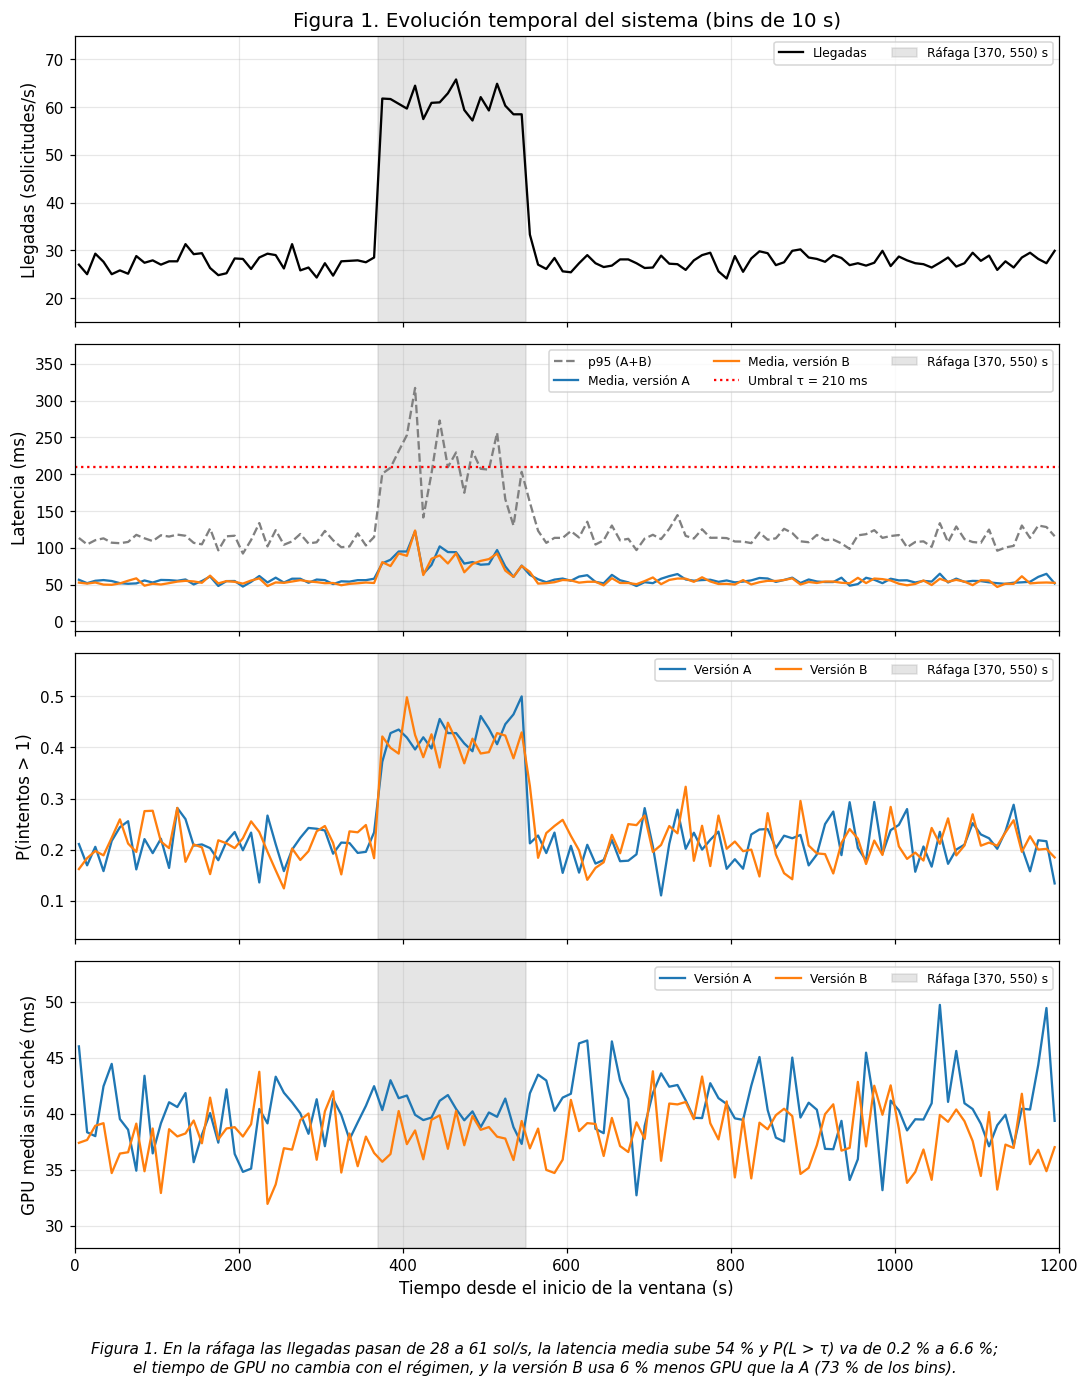

In [ ]:
# Paso 3. Figura 1
ANCHO = 10                                                      # segundos por bin
bin_s = (d_a2.t_llegada_s // ANCHO) * ANCHO + ANCHO / 2        # centro del bin de cada solicitud
por_bin = d_a2.groupby(bin_s)
por_bin_ver = d_a2.groupby([bin_s, "version"])
COLOR = {"A": "tab:blue", "B": "tab:orange"}

fig, ax = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

ax[0].plot(por_bin.size() / ANCHO, color="black", label="Llegadas")
ax[0].set_ylabel("Llegadas (solicitudes/s)")
ax[0].set_title("Figura 1. Evolución temporal del sistema (bins de 10 s)")

ax[1].plot(por_bin.latencia_ms.quantile(0.95), color="grey", linestyle="--", label="p95 (A+B)")
lat = por_bin_ver.latencia_ms.mean().unstack()
rein = por_bin_ver.intentos.apply(lambda s: (s > 1).mean()).unstack()
gpu = por_bin_ver.gpu_sin_cache.mean().unstack()
for v in ["A", "B"]:
    ax[1].plot(lat[v], color=COLOR[v], label=f"Media, versión {v}")
    ax[2].plot(rein[v], color=COLOR[v], label=f"Versión {v}")
    ax[3].plot(gpu[v], color=COLOR[v], label=f"Versión {v}")
ax[1].axhline(tau, color="red", linestyle=":", label=f"Umbral τ = {tau} ms")
ax[1].set_ylabel("Latencia (ms)")
ax[2].set_ylabel("P(intentos > 1)")
ax[3].set_ylabel("GPU media sin caché (ms)")
ax[3].set_xlabel("Tiempo desde el inicio de la ventana (s)")

for a_ in ax:                                                   # ráfaga sombreada y leyenda en cada panel
    a_.axvspan(INI, FIN, color="grey", alpha=0.2, label=f"Ráfaga [{INI}, {FIN}) s")
    a_.margins(y=0.22)
    a_.legend(loc="upper right", fontsize=8, ncol=3)
    a_.set_xlim(0, T_VENTANA)

frac_B_menor = (gpu["B"] < gpu["A"]).mean()                    # bins donde B tiene menos GPU que A
est, raf = contexto.loc["estable"], contexto.loc["rafaga"]
pie_de_figura(fig, 1,
              f"En la ráfaga las llegadas pasan de {est.llegadas_por_s:.0f} a {raf.llegadas_por_s:.0f} sol/s, la latencia media "
              f"sube {cambios.loc['latencia_ms', 'ráfaga vs estable (%)']:.0f} % y P(L > τ) va de {100 * est.P_L_mayor_tau:.1f} % "
              f"a {100 * raf.P_L_mayor_tau:.1f} %;\nel tiempo de GPU no cambia con el régimen, y la versión B usa "
              f"{abs(cambios.loc['gpu_sin_cache', 'B vs A, estable (%)']):.0f} % menos GPU que la A ({100 * frac_B_menor:.0f} % de los bins).")
plt.tight_layout()
guardar_figura(fig, 1)                                          # figuras/figura_1.png
plt.show()

**Conclusión A3.**
- **La ráfaga solo afecta la latencia:** la media sube ≈ 54 % y la espera en cola pasa de ≈ 3 a ≈ 32 ms, mientras GPU, red y tamaño no cambian. El deterioro es por carga, no por el modelo.
- **La versión B usa ≈ 6 % menos GPU que la A** en ambos regímenes. Es una pista descriptiva; la prueba formal es F3.
- **Forma:** latencia, GPU y tamaño son asimétricas a la derecha (media > mediana, asimetría > 0) y con colas pesadas; `red_ms` tiene asimetría y curtosis ≈ 0, compatible con una normal (se prueba en C3).

# Parte B - Llegadas, fallos y reintentos (14 pts)

### B1. Modelo del proceso de llegadas

**Modelo propuesto.** Si las solicitudes llegan de forma independiente y con tasa constante λ (régimen estable), las llegadas forman un **proceso de Poisson homogéneo**. Eso implica dos cosas que se pueden contrastar con los datos:
- los **tiempos entre llegadas** son independientes y siguen una **Exponencial(λ)**, con media 1/λ;
- el **número de llegadas** en un intervalo de Δ segundos sigue una **Poisson(λΔ)**, con media = varianza = λΔ.

El régimen estable son dos tramos separados ([0, 370) y [550, 1200) s), así que los tiempos entre llegadas se calculan **dentro de cada tramo**, para no contar el hueco de la ráfaga como un tiempo entre llegadas.

In [ ]:
# Paso 1. Datos del régimen estable: tiempos entre llegadas y conteos por segundo
DELTA = 1.0                                                     # ancho (s) de los intervalos para contar llegadas
tramos = [(0, INI), (FIN, T_VENTANA)]                           # los dos tramos del régimen estable
T_EST = sum(b - a for a, b in tramos)                           # tiempo total observado: 1020 s

entre_llegadas, conteos_b1 = [], []
for a, b in tramos:
    t = np.sort(df_estable.t_llegada_s[(df_estable.t_llegada_s >= a) & (df_estable.t_llegada_s < b)].to_numpy())
    entre_llegadas.append(np.diff(t))                           # tiempos entre llegadas consecutivas DEL MISMO tramo
    conteos_b1.append(np.histogram(t, bins=np.arange(a, b + DELTA, DELTA))[0])   # llegadas en cada segundo
X = np.concatenate(entre_llegadas)                              # tiempos entre llegadas (s)
C = np.concatenate(conteos_b1)                                  # conteos por intervalo de 1 s
n_lleg = len(df_estable)

print(f"Llegadas: {n_lleg} en {T_EST:.0f} s | tiempos entre llegadas: {len(X)} | intervalos de {DELTA:.0f} s: {len(C)}")
print(f"Tiempo entre llegadas: media = {1000 * X.mean():.2f} ms, desv. est. = {1000 * X.std(ddof=1):.2f} ms, "
      f"CV = {X.std(ddof=1) / X.mean():.3f}  (Exponencial: CV = 1)")
print(f"Conteos por segundo: media = {C.mean():.2f}, varianza = {C.var(ddof=1):.2f}, "
      f"varianza/media = {C.var(ddof=1) / C.mean():.3f}  (Poisson: = 1)")

Llegadas: 28162 en 1020 s | tiempos entre llegadas: 28160 | intervalos de 1 s: 1020
Tiempo entre llegadas: media = 36.22 ms, desv. est. = 36.39 ms, CV = 1.005  (Exponencial: CV = 1)
Conteos por segundo: media = 27.61, varianza = 29.19, varianza/media = 1.057  (Poisson: = 1)


**Paso 2. Estimación de λ.** El estimador de máxima verosimilitud de la tasa es $\hat\lambda = N/T$ (llegadas entre tiempo observado), equivalente a $1/\bar X$ con los tiempos entre llegadas. Se reportan dos intervalos exactos al nivel 1 − α del grupo:
- **por conteos:** N ~ Poisson(λT), intervalo de Garwood con cuantiles χ²;
- **por tiempos entre llegadas:** si $X_i$ ~ Exp(λ), entonces $2\lambda\sum X_i \sim \chi^2_{2n}$.

También se da el intervalo para la media entre llegadas, 1/λ.

In [ ]:
# Paso 2. Estimación puntual e intervalos de confianza de lambda
lam_hat = n_lleg / T_EST                                        # MLE con conteos: N / T
lam_hat_x = 1 / X.mean()                                        # MLE con tiempos entre llegadas: 1 / media

# IC exacto por conteos (Garwood): N ~ Poisson(lambda * T)
lam_li = stats.chi2.ppf(alpha / 2, 2 * n_lleg) / (2 * T_EST)
lam_ls = stats.chi2.ppf(1 - alpha / 2, 2 * n_lleg + 2) / (2 * T_EST)

# IC exacto por tiempos entre llegadas: 2 * lambda * sum(X) ~ chi2 con 2n grados de libertad
n_x, suma_x = len(X), X.sum()
lamx_li = stats.chi2.ppf(alpha / 2, 2 * n_x) / (2 * suma_x)
lamx_ls = stats.chi2.ppf(1 - alpha / 2, 2 * n_x) / (2 * suma_x)

print("lambda (solicitudes/s), por conteos:          ", formatear_intervalo(lam_hat, lam_li, lam_ls, "Poisson exacto (Garwood)"))
print("lambda (solicitudes/s), por entre llegadas:   ", formatear_intervalo(lam_hat_x, lamx_li, lamx_ls, "chi2 exacto, Exponencial"))
print("media entre llegadas 1/lambda (ms):           ", formatear_intervalo(1000 / lam_hat_x, 1000 / lamx_ls, 1000 / lamx_li, "chi2 exacto, Exponencial", 2))

lambda (solicitudes/s), por conteos:           27.610  [27.340, 27.882]  (IC 90%, método: Poisson exacto (Garwood))
lambda (solicitudes/s), por entre llegadas:    27.609  [27.339, 27.880]  (IC 90%, método: chi2 exacto, Exponencial)
media entre llegadas 1/lambda (ms):            36.22  [35.87, 36.58]  (IC 90%, método: chi2 exacto, Exponencial)


**Paso 3. Validación (dos vías cuantitativas, una por cada parte del modelo).**
1. **Tiempos entre llegadas vs. Exponencial(λ̂):** prueba de Kolmogórov-Smirnov. Como λ se estimó con los mismos datos, el valor p de la KS clásica sería demasiado optimista; por eso se calcula por **bootstrap paramétrico** (se simulan muestras Exponenciales con λ̂, se re-estima λ en cada una y se recalcula el estadístico). Además se revisa la **independencia** con la autocorrelación de orden 1.
2. **Conteos por segundo vs. Poisson(λ̂):** prueba **χ² de bondad de ajuste**, agrupando las colas para que cada clase tenga frecuencia esperada ≥ 5, y el **índice de dispersión** (varianza/media = 1).

In [ ]:
# Paso 3a. Tiempos entre llegadas: KS contra Exponencial(lambda estimada), valor p por bootstrap paramétrico
B_BOOT = 1000                                                   # réplicas del bootstrap
ks_obs = stats.kstest(X, "expon", args=(0, 1 / lam_hat_x)).statistic
ks_boot = np.empty(B_BOOT)
for b in range(B_BOOT):
    xb = rng.exponential(1 / lam_hat_x, size=n_x)               # muestra simulada bajo H0
    ks_boot[b] = stats.kstest(xb, "expon", args=(0, xb.mean())).statistic   # se re-estima lambda en cada réplica
p_ks = (1 + (ks_boot >= ks_obs).sum()) / (B_BOOT + 1)
print(f"KS tiempos entre llegadas: D = {ks_obs:.4f}, p (bootstrap paramétrico) = {p_ks:.3f} "
      f"-> {'se rechaza' if p_ks < alpha else 'no se rechaza'} la Exponencial")

# Independencia: autocorrelación de orden 1 de los tiempos entre llegadas (bajo independencia ~ N(0, 1/n))
rho1 = np.corrcoef(X[:-1], X[1:])[0, 1]
z_rho = rho1 * np.sqrt(n_x)
print(f"Autocorrelación de orden 1: {rho1:.4f}, z = {z_rho:.2f}, p = {2 * stats.norm.sf(abs(z_rho)):.3f}")

KS tiempos entre llegadas: D = 0.0055, p (bootstrap paramétrico) = 0.154 -> no se rechaza la Exponencial
Autocorrelación de orden 1: -0.0028, z = -0.47, p = 0.641


In [ ]:
# Paso 3b. Conteos por segundo: chi^2 de bondad de ajuste contra Poisson(lambda * DELTA)
mu = lam_hat * DELTA                                            # media esperada por intervalo
k_lo, k_hi = int(stats.poisson.ppf(0.005, mu)), int(stats.poisson.ppf(0.995, mu))
clases = np.arange(k_lo, k_hi + 1)                              # clases centrales; las colas se agrupan en los extremos
obs = np.array([(C <= k_lo).sum()] + [(C == k).sum() for k in clases[1:-1]] + [(C >= k_hi).sum()])
p_cl = np.concatenate([[stats.poisson.cdf(k_lo, mu)], stats.poisson.pmf(clases[1:-1], mu), [stats.poisson.sf(k_hi - 1, mu)]])
esp = len(C) * p_cl

# Agrupa clases vecinas hasta que todas tengan frecuencia esperada >= 5
while esp.min() < 5:
    i = int(np.argmin(esp)); j = i + 1 if i < len(esp) - 1 else i - 1
    obs[j] += obs[i]; esp[j] += esp[i]
    obs, esp = np.delete(obs, i), np.delete(esp, i)

chi2_obs = ((obs - esp) ** 2 / esp).sum()
gl_chi2 = len(obs) - 1 - 1                                      # -1 por la suma fija y -1 por estimar lambda
p_chi2 = stats.chi2.sf(chi2_obs, gl_chi2)
print(f"Chi^2 conteos por segundo: X2 = {chi2_obs:.2f}, gl = {gl_chi2}, p = {p_chi2:.3f} "
      f"-> {'se rechaza' if p_chi2 < alpha else 'no se rechaza'} la Poisson")

D_b1 = ((C - C.mean()) ** 2 / C.mean()).sum()                   # índice de dispersión (como en A2, ahora con bins de 1 s)
p_disp_b1 = 2 * min(stats.chi2.sf(D_b1, len(C) - 1), stats.chi2.cdf(D_b1, len(C) - 1))   # bilateral: sobre o subdispersión
print(f"Índice de dispersión: D = {D_b1:.1f}, gl = {len(C) - 1}, varianza/media = {C.var(ddof=1) / C.mean():.3f}, p = {p_disp_b1:.3f}")

Chi^2 conteos por segundo: X2 = 33.61, gl = 25, p = 0.117 -> no se rechaza la Poisson
Índice de dispersión: D = 1077.3, gl = 1019, varianza/media = 1.057, p = 0.200


**Gráfica de apoyo.** A la izquierda, el QQ-plot de los tiempos entre llegadas contra la Exponencial(λ̂): si el modelo es bueno, los puntos caen sobre la diagonal. A la derecha, la frecuencia observada de los conteos por segundo frente a la Poisson(λ̂).

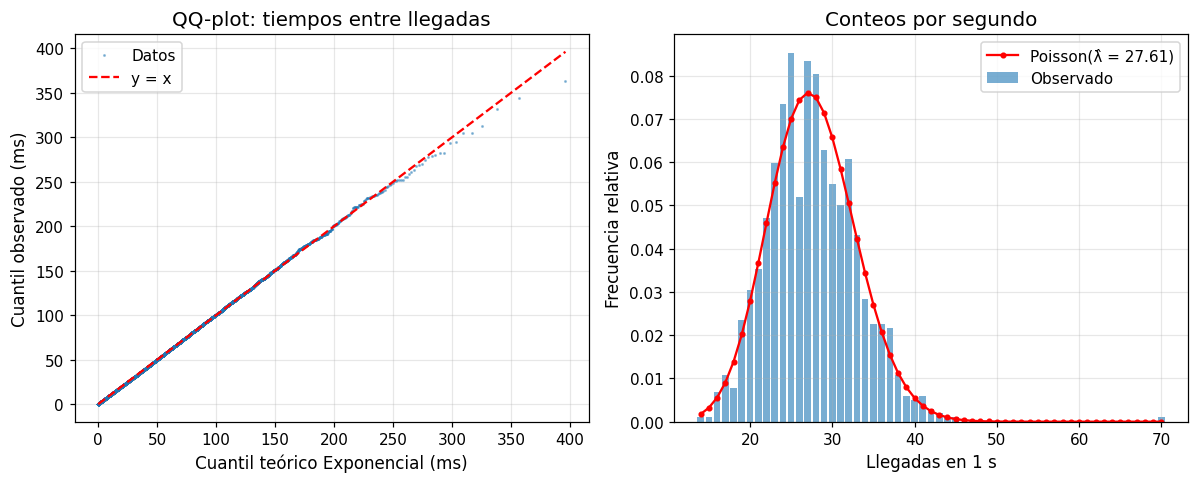

In [ ]:
# Paso 4. Gráfica de apoyo (no es una figura numerada del enunciado)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

prob = (np.arange(1, n_x + 1) - 0.5) / n_x                      # probabilidades de los cuantiles
teo = stats.expon.ppf(prob, scale=1 / lam_hat_x) * 1000         # cuantiles teóricos (ms)
ax[0].plot(teo, np.sort(X) * 1000, ".", ms=2, alpha=0.4, label="Datos")
ax[0].plot([0, teo.max()], [0, teo.max()], "r--", label="y = x")
ax[0].set_xlabel("Cuantil teórico Exponencial (ms)")
ax[0].set_ylabel("Cuantil observado (ms)")
ax[0].set_title("QQ-plot: tiempos entre llegadas")
ax[0].legend()

k = np.arange(C.min(), C.max() + 1)
ax[1].bar(k, [(C == v).mean() for v in k], color="tab:blue", alpha=0.6, label="Observado")
ax[1].plot(k, stats.poisson.pmf(k, mu), "ro-", ms=3, label=f"Poisson(λ̂ = {mu:.2f})")
ax[1].set_xlabel("Llegadas en 1 s")
ax[1].set_ylabel("Frecuencia relativa")
ax[1].set_title("Conteos por segundo")
ax[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "apoyo_B1.png"), bbox_inches="tight")
plt.show()

**Conclusión B1.** En el régimen estable las llegadas son compatibles con un proceso de Poisson homogéneo: los tiempos entre llegadas se ajustan a una Exponencial y no están correlacionados, y los conteos por segundo se ajustan a una Poisson con varianza ≈ media. La tasa estimada es λ̂ ≈ 27,6 solicitudes/s (ver intervalos arriba); este λ̂ es el que se usa en B4 y en la simulación de la Parte G.

### B2. Bloques de 100 solicitudes

**Modelo propuesto.** Sea $Y_j$ el número de solicitudes del bloque $j$ (100 solicitudes consecutivas) que necesitaron más de un intento. Si dentro de un régimen
cada solicitud necesita reintento de forma **independiente** y con la **misma probabilidad** $p$, entonces
$$Y_j \sim \text{Binomial}(100,\,p), \qquad E[Y_j] = 100p, \qquad \text{Var}(Y_j) = 100p(1-p).$$
Se ajusta una Binomial **por régimen**, porque A2 mostró que los reintentos se duplican en la ráfaga. Los bloques se arman **dentro de cada tramo** (igual que en B1,
para no mezclar solicitudes separadas por el hueco de la ráfaga) y se descartan las solicitudes sobrantes al final de cada tramo, que no completan un bloque.

Dos cosas pueden fallar y se contrastan con los datos: que $p$ no sea constante dentro del régimen, o que haya dependencia entre solicitudes (ráfagas de fallos).
Cualquiera de las dos haría la varianza de $Y_j$ **mayor** que $100p(1-p)$ (sobredispersión).

In [ ]:
# Paso 1. Bloques consecutivos de 100 solicitudes y número de solicitudes con más de un intento en cada bloque
TAM_BLOQUE = 100                                                # solicitudes por bloque (enunciado)


def contar_por_bloque(d, tramos_):
    """Y_j = solicitudes con intentos > 1 en cada bloque de 100 consecutivas; los bloques se arman dentro de cada tramo.
    Devuelve (Y, instantes inicial y final de cada bloque, solicitudes descartadas)."""
    ys, lim, descartadas = [], [], 0
    for a, b in tramos_:
        t = d[(d.t_llegada_s >= a) & (d.t_llegada_s < b)].sort_values("t_llegada_s")   # solicitudes del tramo, en orden de llegada
        reint = (t.intentos.to_numpy() > 1).astype(int)         # 1 si la solicitud necesitó más de un intento
        k = len(reint) // TAM_BLOQUE                            # bloques completos que caben en el tramo
        ys.append(reint[:k * TAM_BLOQUE].reshape(k, TAM_BLOQUE).sum(axis=1))   # reintentos por bloque
        ti = t.t_llegada_s.to_numpy()[:k * TAM_BLOQUE].reshape(k, TAM_BLOQUE)  # instantes de llegada de cada bloque
        lim.append(np.column_stack([ti[:, 0], ti[:, -1]]))      # (primera, última) llegada de cada bloque
        descartadas += len(reint) - k * TAM_BLOQUE              # solicitudes que no completan un bloque
    return np.concatenate(ys), np.vstack(lim), descartadas


Y, LIM = {}, {}                                                 # Y[reg]: reintentos por bloque; LIM[reg]: (inicio, fin) en s de cada bloque
Y["estable"], LIM["estable"], desc_e = contar_por_bloque(df_estable, tramos)    # `tramos` = los dos tramos del régimen estable (B1)
Y["rafaga"], LIM["rafaga"], desc_r = contar_por_bloque(df_rafaga, [(INI, FIN)])

for reg, descartadas in [("estable", desc_e), ("rafaga", desc_r)]:
    y = Y[reg]
    print(f"{reg:8s} bloques = {len(y):3d} (solicitudes descartadas: {descartadas}) | "
          f"media de Y = {y.mean():5.2f} | varianza de Y = {y.var(ddof=1):5.2f} | mín = {y.min()}, máx = {y.max()}")

estable  bloques = 281 (solicitudes descartadas: 62) | media de Y = 21.21 | varianza de Y = 18.72 | mín = 10, máx = 44
rafaga   bloques = 109 (solicitudes descartadas: 67) | media de Y = 41.83 | varianza de Y = 25.46 | mín = 29, máx = 53


**Paso 2. Estimación de $p$.** El estimador de máxima verosimilitud es la proporción global de solicitudes con reintento, $\hat p = \sum_j Y_j / (100K)$, con $K$ bloques.
Si las solicitudes son independientes, $\sum_j Y_j \sim \text{Binomial}(100K, p)$ y se obtiene un intervalo **exacto de Clopper-Pearson** al nivel 1 − α del grupo.

In [ ]:
# Paso 2. Estimación puntual e intervalo de confianza de p, por régimen
def estimar_p(y):
    """MLE de p y su intervalo exacto de Clopper-Pearson al nivel 1 - alpha."""
    n = TAM_BLOQUE * len(y)                                     # solicitudes totales usadas
    x = int(y.sum())                                            # solicitudes con reintento
    li = stats.beta.ppf(alpha / 2, x, n - x + 1) if x > 0 else 0.0
    ls = stats.beta.ppf(1 - alpha / 2, x + 1, n - x) if x < n else 1.0
    return x / n, li, ls, x, n


EST = {reg: estimar_p(Y[reg]) for reg in Y}                     # reg -> (p_hat, inferior, superior, x, n)
for reg, (p_hat, li, ls, x, n) in EST.items():
    print(f"p ({reg:8s}): ", formatear_intervalo(p_hat, li, ls, "Clopper-Pearson"), f"| {x} de {n} solicitudes")

p (estable ):  0.212  [0.208, 0.216]  (IC 90%, método: Clopper-Pearson) | 5959 de 28100 solicitudes
p (rafaga  ):  0.418  [0.410, 0.426]  (IC 90%, método: Clopper-Pearson) | 4559 de 10900 solicitudes


**Paso 3. Validación (dos vías cuantitativas, más la independencia entre bloques).**
1. **χ² de bondad de ajuste** de la distribución de $Y_j$ contra Binomial(100, $\hat p$), agrupando clases hasta que cada una tenga frecuencia esperada ≥ 5
   (grados de libertad: clases − 1 − 1, por haber estimado $p$).
2. **Índice de dispersión** $D=\sum_j (Y_j-\bar Y)^2 / (100\hat p(1-\hat p))$, que bajo el modelo sigue aprox. $\chi^2_{K-1}$ (varianza/varianza binomial = 1). El valor p es bilateral:
   un valor grande indicaría sobredispersión y uno pequeño subdispersión.
3. **Independencia entre bloques:** autocorrelación de orden 1 de $Y_j$ (bajo independencia es aprox. $N(0, 1/K)$).

In [ ]:
# Paso 3. Validación del modelo Binomial(100, p) en cada régimen
def chi2_binomial(y, n, p):
    """Chi^2 de bondad de ajuste de los conteos y contra Binomial(n, p); clases agrupadas hasta tener esperada >= 5."""
    K = len(y)
    obs_k = np.bincount(y, minlength=n + 1)                     # frecuencia observada de cada valor 0..n
    esp_k = K * stats.binom.pmf(np.arange(n + 1), n, p)         # frecuencia esperada bajo el modelo
    obs, esp, o_acc, e_acc = [], [], 0, 0.0
    for o, e in zip(obs_k, esp_k):                              # recorre las clases de izquierda a derecha
        o_acc, e_acc = o_acc + o, e_acc + e                     # acumula hasta que la esperada llegue a 5
        if e_acc >= 5:
            obs.append(o_acc); esp.append(e_acc); o_acc, e_acc = 0, 0.0
    if e_acc > 0:                                               # el resto de la cola derecha se pega a la última clase
        obs[-1] += o_acc; esp[-1] += e_acc
    obs, esp = np.array(obs), np.array(esp)
    X2 = ((obs - esp) ** 2 / esp).sum()
    gl = len(obs) - 1 - 1                                       # -1 por la suma fija y -1 por estimar p
    return X2, gl, stats.chi2.sf(X2, gl)


filas_val = []
for reg, y in Y.items():
    K, p_hat = len(y), EST[reg][0]
    X2, gl, p_chi2 = chi2_binomial(y, TAM_BLOQUE, p_hat)        # vía 1: bondad de ajuste
    var_bin = TAM_BLOQUE * p_hat * (1 - p_hat)                  # varianza que predice el modelo
    D_b2 = ((y - y.mean()) ** 2).sum() / var_bin                # vía 2: índice de dispersión
    p_disp = 2 * min(stats.chi2.sf(D_b2, K - 1), stats.chi2.cdf(D_b2, K - 1))
    rho1 = np.corrcoef(y[:-1], y[1:])[0, 1]                     # independencia entre bloques consecutivos
    z_rho = rho1 * np.sqrt(K)
    filas_val.append({"régimen": reg, "K": K, "media Y": y.mean(), "100·p̂": TAM_BLOQUE * p_hat,
                      "var Y": y.var(ddof=1), "var Binomial": var_bin, "var/var Bin": y.var(ddof=1) / var_bin,
                      "χ² (gl)": f"{X2:.1f} ({gl})", "p χ²": p_chi2, "p dispersión": p_disp,
                      "autocorr. lag 1": rho1, "p autocorr.": 2 * stats.norm.sf(abs(z_rho))})
validacion = pd.DataFrame(filas_val).set_index("régimen")
print(validacion.round(3).T.to_string())
print(f"\nNivel de decisión α = {alpha}: un valor p < α rechaza el modelo.")

régimen            estable    rafaga
K                      281       109
media Y             21.206    41.826
100·p̂              21.206    41.826
var Y               18.722     25.46
var Binomial        16.709    24.332
var/var Bin           1.12     1.046
χ² (gl)          13.8 (15)  8.8 (13)
p χ²                 0.544     0.787
p dispersión         0.162     0.703
autocorr. lag 1      0.061    -0.108
p autocorr.           0.31     0.261

Nivel de decisión α = 0.1: un valor p < α rechaza el modelo.


**Paso 4. Contraste entre regímenes y explicación de la discrepancia.** Se comprueba (i) que $p$ es constante **dentro** de cada régimen (si no, el modelo Binomial tendría sobredispersión),
(ii) qué pasa si se usa el modelo del régimen estable para describir la ráfaga, y (iii) cuánto cambia $p$ entre regímenes, con su intervalo.

In [ ]:
# Paso 4a. ¿p es constante dentro de cada régimen? Se parten los bloques en tres grupos consecutivos y se compara la proporción (chi^2 de homogeneidad)
for reg, y in Y.items():
    grupos = np.array_split(y, 3)                               # tres tramos consecutivos de bloques
    tabla = np.array([[g.sum(), TAM_BLOQUE * len(g) - g.sum()] for g in grupos])   # [con reintento, sin reintento] por grupo
    chi2_h, p_h, _, _ = stats.chi2_contingency(tabla)
    props = ", ".join(f"{g.sum() / (TAM_BLOQUE * len(g)):.3f}" for g in grupos)
    print(f"{reg:8s} proporción por tercios: {props} | chi2 de homogeneidad p = {p_h:.3f} "
          f"-> {'p cambia' if p_h < alpha else 'p constante'}")

# Paso 4b. Usar el modelo del régimen estable (p estable) para describir la ráfaga
p_e, p_r = EST["estable"][0], EST["rafaga"][0]
y_r = Y["rafaga"]
z_med = (y_r.mean() - TAM_BLOQUE * p_e) / np.sqrt(TAM_BLOQUE * p_e * (1 - p_e) / len(y_r))   # media observada frente a la que predice p_e
q999 = stats.binom.ppf(0.999, TAM_BLOQUE, p_e)                  # cuantil 99,9 % de la Binomial(100, p estable)
frac_sobre = (y_r > q999).mean()                                # bloques de la ráfaga por encima de ese cuantil
print(f"\nModelo del régimen estable aplicado a la ráfaga: se esperaría E[Y] = {TAM_BLOQUE * p_e:.1f} y se observa {y_r.mean():.1f} "
      f"(z = {z_med:.1f}); {100 * frac_sobre:.0f} % de los bloques de la ráfaga superan el cuantil 99,9 % ({q999:.0f}).")

# Paso 4c. Diferencia y cociente de proporciones entre regímenes
(pe_hat, _, _, xe, ne), (pr_hat, _, _, xr, nr) = EST["estable"], EST["rafaga"]
dif = pr_hat - pe_hat
ee = np.sqrt(pe_hat * (1 - pe_hat) / ne + pr_hat * (1 - pr_hat) / nr)      # error estándar de la diferencia
zc = stats.norm.ppf(1 - alpha / 2)
p_dif = stats.chi2_contingency([[xe, ne - xe], [xr, nr - xr]], correction=False)[1]
print(formatear_intervalo(dif, dif - zc * ee, dif + zc * ee, "Wald para diferencia de proporciones"), f"| p (chi2) = {p_dif:.1e}")
print(f"Cociente p(ráfaga)/p(estable) = {pr_hat / pe_hat:.2f}")

estable  proporción por tercios: 0.210, 0.211, 0.215 | chi2 de homogeneidad p = 0.681 -> p constante
rafaga   proporción por tercios: 0.415, 0.411, 0.428 | chi2 de homogeneidad p = 0.326 -> p constante

Modelo del régimen estable aplicado a la ráfaga: se esperaría E[Y] = 21.2 y se observa 41.8 (z = 52.7); 90 % de los bloques de la ráfaga superan el cuantil 99,9 % (35).
0.206  [0.197, 0.215]  (IC 90%, método: Wald para diferencia de proporciones) | p (chi2) = 0.0e+00
Cociente p(ráfaga)/p(estable) = 1.97


**Paso 4d. Bloques atípicos.** El índice de dispersión del régimen estable queda algo por encima de 1. Para ver si es un problema general del modelo o lo causan pocos bloques,
se busca cada bloque cuyo conteo es demasiado extremo para su Binomial (valor p bilateral < α/K, con la corrección de Bonferroni porque se prueban K bloques a la vez).
Para cada bloque marcado se revisa **qué pasó en su ventana de tiempo**: cuántas llegadas hubo frente a lo esperado y qué proporción de reintentos tuvo.
Finalmente se repite la validación sin esos bloques, para medir cuánto dependen las conclusiones de ellos.

In [ ]:
# Paso 4d. Bloques atípicos y sensibilidad
LAM = {"estable": lam_hat, "rafaga": len(df_rafaga) / (FIN - INI)}      # tasa de llegadas de cada régimen (sol/s); lam_hat viene de B1
marcados = {}                                                   # reg -> índices de bloques marcados
for reg, y in Y.items():
    K, p_hat = len(y), EST[reg][0]
    p_blq = 2 * np.minimum(stats.binom.sf(y - 1, TAM_BLOQUE, p_hat), stats.binom.cdf(y, TAM_BLOQUE, p_hat))   # p bilateral de cada bloque
    marcados[reg] = np.flatnonzero(p_blq < alpha / K)           # Bonferroni
    print(f"{reg:8s} bloques marcados (p < alpha/K = {alpha / K:.1e}): {len(marcados[reg])}")
    for j in marcados[reg]:
        a, b = LIM[reg][j]                                      # ventana de tiempo del bloque
        sub = d_a2[(d_a2.t_llegada_s >= a) & (d_a2.t_llegada_s <= b)]
        esperadas = LAM[reg] * (b - a)                          # llegadas que predice la tasa del régimen en esa ventana
        x_w, n_w = int((sub.intentos > 1).sum()), len(sub)
        print(f"  bloque {j}: [{a:.2f}, {b:.2f}] s, Y = {y[j]}, p del bloque = {p_blq[j]:.1e} | llegadas: {n_w} (esperadas {esperadas:.0f}, "
              f"P(N >= {n_w}) = {stats.poisson.sf(n_w - 1, esperadas):.1e}) | reintentos: {x_w / n_w:.2f}")
        for otro in ["estable", "rafaga"]:                      # ¿con qué régimen es compatible la proporción de reintentos de la ventana?
            po = EST[otro][0]
            pv = 2 * min(stats.binom.sf(x_w - 1, n_w, po), stats.binom.cdf(x_w, n_w, po))
            print(f"           ¿compatible con la proporción del régimen {otro} (p = {po:.3f})? p = {pv:.1e}")

print("\nValidación SIN los bloques marcados (sensibilidad):")
for reg, y in Y.items():
    y2 = np.delete(y, marcados[reg]); K2 = len(y2)
    p2 = y2.sum() / (TAM_BLOQUE * K2)
    v2 = TAM_BLOQUE * p2 * (1 - p2)
    D2 = ((y2 - y2.mean()) ** 2).sum() / v2
    pd2 = 2 * min(stats.chi2.sf(D2, K2 - 1), stats.chi2.cdf(D2, K2 - 1))
    print(f"  {reg:8s} K = {K2}, p̂ = {p2:.4f} (antes {EST[reg][0]:.4f}), var/var Bin = {y2.var(ddof=1) / v2:.3f} "
          f"(antes {validacion.loc[reg, 'var/var Bin']:.3f}), p(dispersión) = {pd2:.3f} (antes {validacion.loc[reg, 'p dispersión']:.3f})")

estable  bloques marcados (p < alpha/K = 3.6e-04): 1
  bloque 101: [550.00, 551.97] s, Y = 44, p del bloque = 5.4e-07 | llegadas: 100 (esperadas 54, P(N >= 100) = 2.0e-08) | reintentos: 0.44
           ¿compatible con la proporción del régimen estable (p = 0.212)? p = 5.4e-07
           ¿compatible con la proporción del régimen rafaga (p = 0.418)? p = 7.3e-01
rafaga   bloques marcados (p < alpha/K = 9.2e-04): 0

Validación SIN los bloques marcados (sensibilidad):
  estable  K = 280, p̂ = 0.2112 (antes 0.2121), var/var Bin = 1.015 (antes 1.120), p(dispersión) = 0.834 (antes 0.162)
  rafaga   K = 109, p̂ = 0.4183 (antes 0.4183), var/var Bin = 1.046 (antes 1.046), p(dispersión) = 0.703 (antes 0.703)


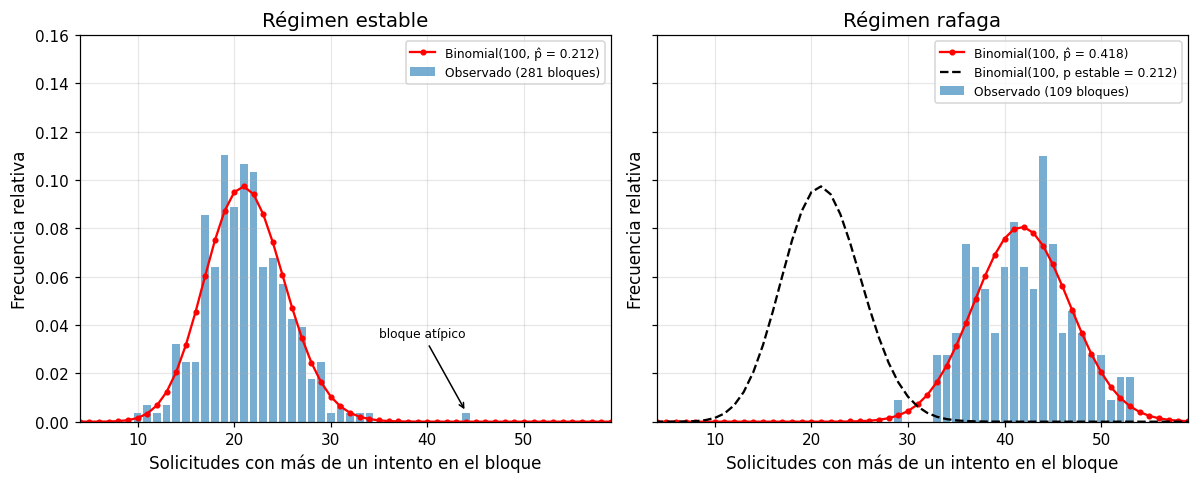

In [ ]:
# Paso 5. Gráfica de apoyo distribución de Y por régimen frente al modelo
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)    # mismo eje X para comparar los dos regímenes
x_lo = max(0, min(y.min() for y in Y.values()) - 6)             # límites del eje X que dejan ver todos los bloques
x_hi = min(TAM_BLOQUE, max(y.max() for y in Y.values()) + 6)
for a_, reg in zip(ax, ["estable", "rafaga"]):
    y, p_hat = Y[reg], EST[reg][0]
    k = np.arange(0, TAM_BLOQUE + 1)
    vals = np.arange(y.min(), y.max() + 1)
    a_.bar(vals, [(y == v).mean() for v in vals], color="tab:blue", alpha=0.6, label=f"Observado ({len(y)} bloques)")
    a_.plot(k, stats.binom.pmf(k, TAM_BLOQUE, p_hat), "ro-", ms=3, label=f"Binomial(100, p̂ = {p_hat:.3f})")
    if reg == "rafaga":                                         # en la ráfaga también se muestra el modelo del régimen estable
        a_.plot(k, stats.binom.pmf(k, TAM_BLOQUE, p_e), "k--", label=f"Binomial(100, p estable = {p_e:.3f})")
    for j in marcados[reg]:                                     # señala los bloques atípicos del paso 4d
        a_.annotate("bloque atípico", xy=(y[j], 0.004), xytext=(y[j] - 9, 0.035), fontsize=8,
                    arrowprops=dict(arrowstyle="->"))
    a_.set_xlim(x_lo, x_hi)
    a_.set_ylim(0, 0.16)                                        # deja espacio arriba para la leyenda
    a_.set_xlabel("Solicitudes con más de un intento en el bloque")
    a_.set_ylabel("Frecuencia relativa")
    a_.set_title(f"Régimen {reg}")
    a_.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "apoyo_B2.png"), bbox_inches="tight")
plt.show()

### B3. Modelo de la variable intentos

### B4. Reintentos en una ventana de 10 s

# Parte C - Tiempo de cómputo y tiempo de red (14 pts)

### C1. Distribución de G (todas las solicitudes)

### C2. Máxima verosimilitud para la parte continua de G

### C3. ¿red_ms admite un modelo normal?

### C4. Tiempo total de GPU de N solicitudes no cacheadas

# Parte D - Dependencias y esperanza condicional (14 pts)

### D1. Conjunta (clase de tamaño, cache_hit)

### D2. Esperanza condicional

### D3. Modelo lineal para E[G | tam_kb, no caché]

### D4. Covarianza y correlación entre tam_kb y gpu_ms (no cacheadas)

# Parte E - Monitoreo y decisión de alertas (12 pts)

### E1. Sensibilidad y tasa de falsos positivos

### E2. Probabilidad de incidente dada cada regla en producción

### E3. ¿D1 y D2 son condicionalmente independientes?

### E4. Falsas alarmas por día

# Parte F - Inferencia, distribuciones muestrales y comparación de versiones (16 pts)

### F1. Distribución muestral de la media de latencia_ms

### F2. Intervalo para la latencia media

### F3. Versión B frente a versión A

### F4. Cobertura de intervalos para una proporción

### F5. Tamaño de muestra por versión

### F6. Validación con solicitudes_validacion.csv (día 9)

# Parte G - Simulación y decisión de capacidad (14 pts)

### G1. Simulador de Montecarlo con c GPUs

### G2. Capacidad con la tasa de llegadas multiplicada por g

### G3. Robustez de c*

### G4. Memorando ejecutivo
Se entrega aparte como PDF de una página (E4).